# Leyenda: demo pipeline (D1 -> D2 -> D3)

A short notebook that runs the three deliverables on any folder of images.
The models are loaded from `models/`: nothing is trained here.

```
image -> D1 photo or not? (MobileNetV2, 128x128)
          | not a photo: stop, no caption
          v photo
         D2 denoising (U-Net, applied at 288x288)
          v
         D3 caption (ConvNeXt-Large frozen -> 81 regions -> GRU + attention, beam search)
```

## A. Imports and models

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide the TensorFlow info messages

import json
import time
from pathlib import Path

import imageio.v3 as iio                   # reads any image file (as in deliverable3.ipynb)
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Memory growth: TensorFlow takes the GPU memory it needs, not everything at once.
    tf.config.experimental.set_memory_growth(gpus[0], True)
# Only hides the TensorFlow "tf.function retracing" warnings, which are harmless here (ConvNeXt is called on
# a new image each time). Errors are still shown. This is for the demo output only.
tf.get_logger().setLevel("ERROR")
print("GPU:", [g.name for g in gpus] or "none")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__)

I0000 00:00:1792694213.280669  204482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792694215.583584  204482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.4


### D1: photo or not (deliverable 1)
The model takes RGB pixels in 0-255 resized to 128x128 and gives the probability of "photo".

In [2]:
MODELS = Path("models")                    # all the saved models are here

D1_PATH = MODELS / "final_pretrained.keras"
D1_SIZE, D1_THRESHOLD = 128, 0.5           # input size, and "photo" if the probability is at least 0.5
d1 = keras.models.load_model(D1_PATH, compile=False)   # compile=False: we only predict, no training

### D2: denoising U-Net (deliverable 2)
Only the weights are saved, so the architecture is rebuilt layer by layer (same order as `build_unet` in
`deliverable2.ipynb`), then the weights are loaded. The input size is `None`: the network is fully convolutional,
so it works at any size that is a multiple of 8 (three 2x poolings).

In [3]:
def build_unet_any_size():
    inputs = keras.Input((None, None, 3))                                     # any height and width, RGB in [0, 1]
    # Encoder: convolution, then halve the size (the first two convolutions are kept for the skip connections)
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = keras.layers.MaxPooling2D(2)(c1)
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c2)
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c3)
    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)    # bottleneck
    # Decoder: double the size, concatenate the encoder output of the same size (skip), convolution
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c3])
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c2])
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c1])
    outputs = keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)   # RGB in [0, 1]
    return keras.Model(inputs, outputs, name="unet_any_size")


# Fixed filename: the file loaded by section 13 of deliverable3.ipynb, and the only d2_unet_multi file in git
D2_WEIGHTS = MODELS / "d2_unet_multi_20261019_100436.weights.h5"
d2 = build_unet_any_size()
d2.load_weights(D2_WEIGHTS)

### D3: captioning (deliverable 3)
Three files: the vocabulary, the configuration, and the decoder (GRU + attention). The image encoder is
ConvNeXt-Large with its ImageNet weights, frozen, and it runs on the CPU (as in the deliverable).

In [4]:
D3 = json.loads((MODELS / "d3_final_config.json").read_text())      # sizes, beam width, scores
vocab = json.loads((MODELS / "d3_final_vocab.json").read_text())    # list of words: the index is the word id
word_index = {w: i for i, w in enumerate(vocab)}                    # word -> id
PAD, UNK, START, END = "<pad>", "<unk>", "<start>", "<end>"         # special tokens
VOCAB_SIZE, MAX_LEN = len(vocab), D3["max_len"]
BANNED = [word_index[PAD], word_index[UNK], word_index[START]]      # words the decoder may never write

captioner = keras.models.load_model(MODELS / "d3_final_captioner.keras", compile=False)   # the decoder

ENC = D3["encoder_input"]                                           # 288: image size read by ConvNeXt-Large
with tf.device("/CPU:0"):                                           # CPU: as in deliverable3.ipynb
    encoder = keras.applications.ConvNeXtLarge(include_top=False, weights="imagenet", input_shape=(ENC, ENC, 3))
encoder.trainable = False                                           # frozen: never trained here

### Checks: shapes and parameter counts

In [5]:
# D1 and D2: the shapes come from the models themselves
print(f"D1 {D1_PATH.name}: input {d1.input_shape} -> output {d1.output_shape} | {d1.count_params():,} parameters")
print(f"D2 {D2_WEIGHTS.name}: input {d2.input_shape} -> output {d2.output_shape} | {d2.count_params():,} parameters")
# D2 is fully convolutional: try it on a dummy 288x288 image to see the real output shape
print("D2 on a 288x288 image ->", d2(np.zeros((1, ENC, ENC, 3), np.float32), training=False).shape)

# D3: the encoder gives a 9x9 grid of 1536 numbers, i.e. 81 regions
print(f"Encoder ConvNeXt-Large: input {encoder.input_shape} -> output {encoder.output_shape} | {encoder.count_params():,} parameters")
print(f"Decoder: inputs {[tuple(i.shape) for i in captioner.inputs]} -> output {captioner.output_shape} | {captioner.count_params():,} parameters")
print(f"Vocabulary: {VOCAB_SIZE} words | max caption length {MAX_LEN} | {D3['regions']} regions x {D3['feature_dim']}")
print(f"Beam {D3['beam']}, no repeated {D3['no_repeat_ngram']}-gram | test BLEU-4 {D3['test_bleu4']}, CIDEr-D {D3['test_cider_d']}")

D1 final_pretrained.keras: input (None, 128, 128, 3) -> output (None, 1) | 2,259,265 parameters
D2 d2_unet_multi_20261019_100436.weights.h5: input (None, None, None, 3) -> output (None, None, None, 3) | 426,979 parameters


D2 on a 288x288 image -> (1, 288, 288, 3)
Encoder ConvNeXt-Large: input (None, 288, 288, 3) -> output (None, 9, 9, 1536) | 196,230,336 parameters
Decoder: inputs [(None, 81, 1536), (None, 21)] -> output (None, 21, 5000) | 7,129,736 parameters
Vocabulary: 5000 words | max caption length 22 | 81 regions x 1536
Beam 3, no repeated 2-gram | test BLEU-4 0.301, CIDEr-D 1.124


### Beam search decoder (deliverable 3, section 11.3, copied unchanged)
`decode` writes the captions of a batch of images. It keeps the 3 best partial sentences (beams) at each step, never
writes a word that would repeat a pair of words (`blocked`), and never writes `<pad>`, `<unk>` or `<start>` (`BANNED`).

In [6]:
# How decode works (the code below is copied unchanged from deliverable3.ipynb, section 11.3):
# 1. Beam search: it keeps the 3 best partial sentences (beams) of each image and extends every beam by every word.
# 2. A beam's score is the sum of the log-probabilities of its words; the 3 best of the 3 x 5000 candidates are kept.
# 3. BANNED = <pad>, <unk>, <start>: their probability is set to 0, so they are never written in a sentence.
# 4. No repeated 2-gram: blocked() forbids a word that would write again a pair of words already written.
# 5. A beam that wrote <end> is done: it can only add <pad> at no cost, so its score stays the same.
# The best beam is returned. There is no random choice: same image, same caption.

import weakref

_next_word_fns = weakref.WeakKeyDictionary()


def next_word_scores(model):
    # Compiled function giving the scores of the next word at ONE position t: the model computes all positions, but
    # only (sentences x 5000) numbers are copied back from the GPU instead of (sentences x 21 x 5000).
    if model not in _next_word_fns:
        @tf.function(reduce_retracing=True)
        def scores(f, seq, t):
            return model([f, seq], training=False)[:, t]
        _next_word_fns[model] = scores
    return _next_word_fns[model]


def blocked(words, n):
    # Words that would repeat an n-gram already written (words = indexes written so far).
    if n <= 0 or len(words) < n - 1:
        return []
    prefix = tuple(words[len(words) - n + 1:]) if n > 1 else ()
    return [words[i + n - 1] for i in range(len(words) - n + 1) if tuple(words[i:i + n - 1]) == prefix]


def decode(feats, k=1, no_repeat=0, batch=40):
    # Greedy (k=1) or beam search with k beams; no_repeat=n forbids writing an n-gram twice. Returns word lists.
    L, V, out = MAX_LEN - 1, VOCAB_SIZE, []
    scores_at = next_word_scores(captioner)
    for s in range(0, len(feats), batch):
        f = np.asarray(feats[s:s + batch], dtype=np.float32)
        n = len(f)
        F = np.repeat(f, k, axis=0)                                   # the features of each image, once per beam
        seq = np.zeros((n, k, L), np.int32)                           # input words of each beam (<start> first)
        seq[:, :, 0] = word_index[START]
        score = np.full((n, k), -np.inf)                              # sum of the log-probabilities of each beam
        score[:, 0] = 0.0                                             # at the start, only one beam is alive
        done = np.zeros((n, k), bool)
        words = np.zeros((n, k, L), np.int32)
        for t in range(L):
            logits = scores_at(F, seq.reshape(n * k, L), tf.constant(t)).numpy().astype(np.float64)
            m = logits.max(1, keepdims=True)
            logp = (logits - m - np.log(np.exp(logits - m).sum(1, keepdims=True))).reshape(n, k, V)   # log-softmax
            logp[:, :, BANNED] = -np.inf
            if no_repeat:
                for i in range(n):
                    for j in range(k):
                        if not done[i, j]:
                            b = blocked(list(words[i, j, :t]), no_repeat)
                            if b:
                                logp[i, j, b] = -np.inf
            logp[done] = -np.inf                                      # a finished beam can only add <pad>, for free
            logp[done, word_index[PAD]] = 0.0
            cand = (score[:, :, None] + logp).reshape(n, k * V)      # every beam extended by every word
            top = np.argpartition(-cand, k, axis=1)[:, :k] if k > 1 else cand.argmax(1)[:, None]
            beam, word = top // V, top % V                            # which beam it extends, with which word
            rows = np.arange(n)[:, None]
            score = cand[rows, top]
            seq, words, done = seq[rows, beam], words[rows, beam], done[rows, beam]
            words[:, :, t] = word
            done = done | (word == word_index[END])
            if t + 1 < L:
                seq[:, :, t + 1] = np.where(done, word_index[PAD], word)
            if done.all():
                break
        best = score.argmax(1)
        for i in range(n):
            ws = []
            for x in words[i, best[i]]:
                if x in (word_index[END], word_index[PAD]):
                    break
                ws.append(vocab[x])
            out.append(ws)
    return out

## B. Three functions, each usable alone
All three take an image as a numpy array **RGB, uint8, any size**, as returned by `read_rgb` (grey and RGBA files are
converted to RGB). `denoise` and `caption` also accept the 288x288 float image in [0, 1] given by the previous step.

In [7]:
def read_rgb(source):
    # File path or bytes -> RGB uint8 array (grey or RGBA images are converted to RGB by imageio)
    return np.ascontiguousarray(iio.imread(source, mode="RGB"))


def to_288(img):
    # Any RGB image -> float32 (288, 288, 3) in [0, 1], the size read by ConvNeXt-Large and used for D2
    x = np.asarray(img, np.float32)
    if img.dtype == np.uint8:
        x = x / 255.0                                                    # pixels 0-255 -> 0-1
    if x.shape[:2] != (ENC, ENC):                                        # already 288x288: nothing to resize
        x = tf.image.resize(x[None], [ENC, ENC], antialias=True).numpy()[0]   # antialias: smooth when shrinking
    return x


def classify(img):
    # D1: probability that the image is a photo (the pipeline compares it with D1_THRESHOLD)
    small = Image.fromarray(img).resize((D1_SIZE, D1_SIZE), Image.BILINEAR)   # 128x128, bilinear, as in deliverable 1
    x = np.asarray(small, np.float32)[None]                              # pixels stay 0-255, plus a batch axis
    return float(d1(x, training=False).numpy().ravel()[0])               # one number between 0 and 1


def denoise(img):
    # D2: denoised image, float32 (288, 288, 3) in [0, 1]
    x = to_288(img)                                                      # the U-Net is applied at 288x288
    clean = d2(x[None], training=False).numpy()[0]                       # batch of one image, then remove the batch axis
    return np.clip(clean, 0, 1)                                          # keep valid pixel values


def caption(img):
    # D3: one sentence describing the image
    x = to_288(img)
    with tf.device("/CPU:0"):                                            # ConvNeXt-Large runs on the CPU (see above)
        maps = encoder(x[None] * 255.0, training=False)                  # ConvNeXt expects pixels 0-255; output (1, 9, 9, 1536)
        feats = tf.reshape(maps, (1, D3["regions"], D3["feature_dim"])).numpy()   # 9x9 grid -> 81 regions
    words = decode(feats, D3["beam"], D3["no_repeat_ngram"])[0]          # beam search; [0] = the only image of the batch
    return " ".join(words)

### Test of each function alone
One image of `demo_images/` for each function.

In [8]:
# classify: a photo and a sketch
photo = read_rgb("demo_images/01_clean_photo.png")
sketch = read_rgb("demo_images/06_sketch_not_a_photo.jpg")
print("photo  :", photo.shape, photo.dtype, "-> P(photo) =", round(classify(photo), 3), "(expected: >= 0.5)")
print("sketch :", sketch.shape, sketch.dtype, "-> P(photo) =", round(classify(sketch), 3), "(expected: < 0.5)")

photo  : (480, 640, 3) uint8 -> P(photo) = 0.992 (expected: >= 0.5)
sketch : (583, 411, 3) uint8 -> P(photo) = 0.134 (expected: < 0.5)


input : (640, 480, 3) uint8
output: (288, 288, 3) float32 | min 0.032 max 0.932


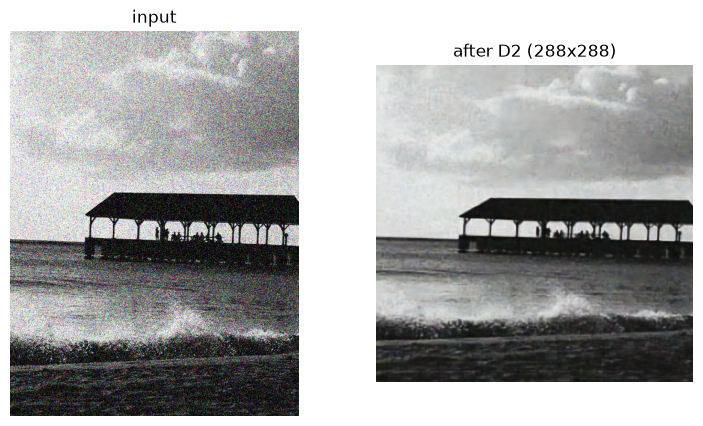

In [9]:
# denoise: a very noisy photo, before and after
noisy = read_rgb("demo_images/03_very_noisy_photo.png")
clean = denoise(noisy)
print("input :", noisy.shape, noisy.dtype)
print("output:", clean.shape, clean.dtype, "| min", round(float(clean.min()), 3), "max", round(float(clean.max()), 3))
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
axes[0].imshow(noisy); axes[0].set_title("input")
axes[1].imshow(clean); axes[1].set_title(f"after D2 ({ENC}x{ENC})")
for ax in axes:
    ax.axis("off")
plt.show()

In [10]:
# caption: one photo, twice (same image must give the same caption: no random sampling)
t0 = time.time()
text1 = caption(photo)
seconds = time.time() - t0
text2 = caption(photo)
print(f"caption: \"{text1}\" ({seconds:.1f} s)")
print("same caption on a second call:", text1 == text2)
# caption also works on the output of denoise (288x288 float image)
print("caption after D2:", caption(denoise(photo)))

caption: "a white house sitting on top of a wooden pier" (4.0 s)
same caption on a second call: True


caption after D2: a house with a wooden dock in the background


## C. The pipeline
`run_pipeline(items)` takes a list of `(name, image)` and chains the three steps:
D1 on every image; a photo goes through D2, then D3 reads the denoised image; a non-photo stops after D1 (no caption).
It shows the input, the denoised image and the caption of each image, and returns the results table.

In [11]:
from IPython.display import display


def run_pipeline(items, show=12):
    # items: list of (name, RGB uint8 image). Returns a table with one row per image.
    rows, panels = [], []                                  # one table row and one figure panel per image
    for name, img in items:
        t0 = time.time()
        p = classify(img)                                  # D1: probability of "photo"
        row = {"image": name, "size": f"{img.shape[1]}x{img.shape[0]}", "P(photo)": round(p, 3)}
        if p < D1_THRESHOLD:                               # not a photo: stop here, no D2 and no D3
            row["D1"], row["caption"] = "not a photo: stop", "-"
            panels.append((name, img, None, f"NOT A PHOTO (P(photo) = {p:.2f})"))
        else:
            clean = denoise(img)                           # D2: denoised image, 288x288
            text = caption(clean)                          # D3: the caption is written from the denoised image
            row["D1"], row["caption"] = "photo", text
            panels.append((name, img, clean, text))
        row["seconds"] = round(time.time() - t0, 1)
        rows.append(row)

    table = pd.DataFrame(rows)
    display(table.style.set_properties(**{"text-align": "left"}))

    n = min(show, len(panels))                             # figure of the first `show` images only (a very tall figure fails)
    if n:
        fig, axes = plt.subplots(n, 2, figsize=(11, 4.6 * n), squeeze=False)
        for r, (name, img, clean, text) in enumerate(panels[:n]):
            axes[r, 0].imshow(img)                         # left: the input as it is
            axes[r, 0].set_title(f"input: {name}", fontsize=10)
            if clean is None:                              # right: a message for a non-photo...
                axes[r, 1].text(0.5, 0.5, text, ha="center", va="center", fontsize=12, color="firebrick")
            else:                                          # ...or the denoised image with its caption
                axes[r, 1].imshow(clean)
                axes[r, 1].set_title(f"after D2 ({ENC}x{ENC})\n\"{text}\"", fontsize=11, color="navy")
            for ax in axes[r]:
                ax.axis("off")
        plt.tight_layout()
        plt.show()
    return table

### Test: one photo and the sketch
The photo must go through D1, D2 and D3; the sketch must stop after D1.

,image,size,P(photo),D1,caption,seconds
0,01_clean_photo.png,640x480,0.992000,photo,a house with a wooden dock in the background,1.900000
1,06_sketch_not_a_photo.jpg,411x583,0.134000,not a photo: stop,-,0.100000


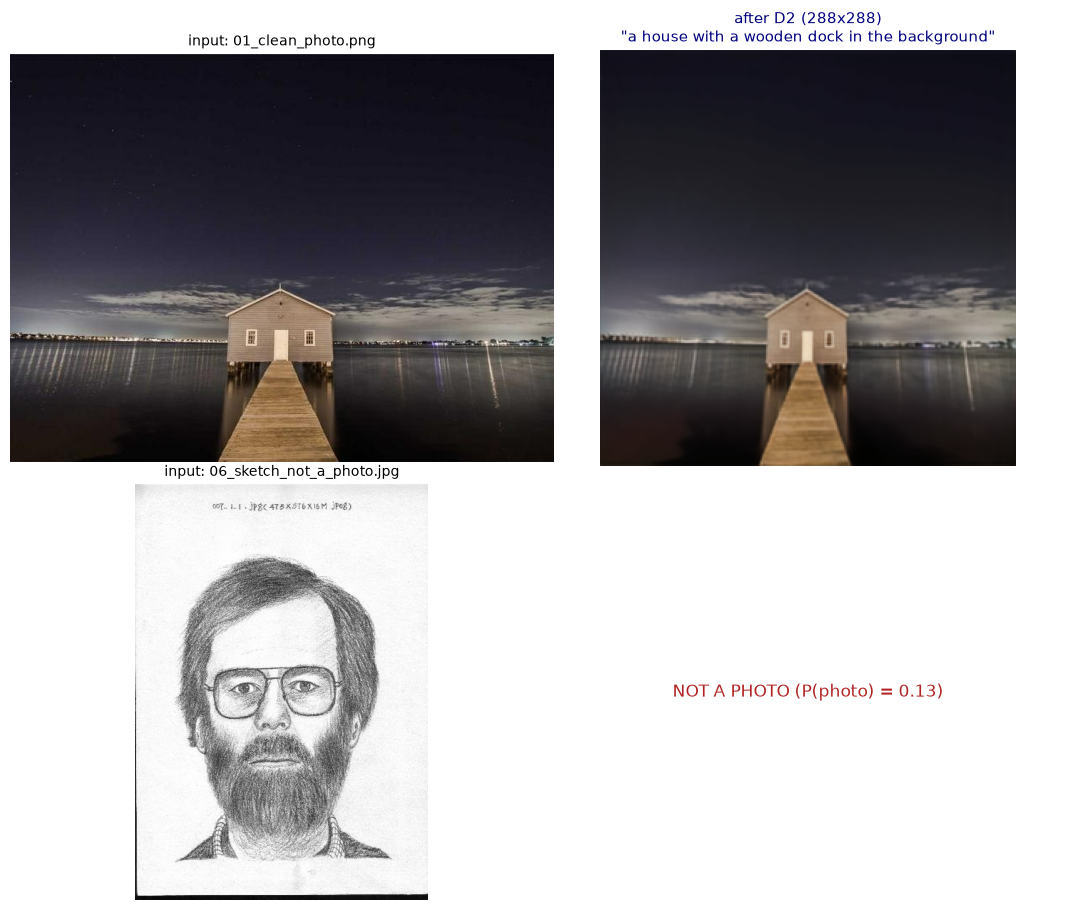

photo goes through D3  : True
sketch stops after D1  : True


In [12]:
test_items = [("01_clean_photo.png", read_rgb("demo_images/01_clean_photo.png")),
              ("06_sketch_not_a_photo.jpg", read_rgb("demo_images/06_sketch_not_a_photo.jpg"))]
test_table = run_pipeline(test_items)

# Checks
print("photo goes through D3  :", test_table.loc[0, "D1"] == "photo" and test_table.loc[0, "caption"] != "-")
print("sketch stops after D1  :", test_table.loc[1, "D1"] == "not a photo: stop" and test_table.loc[1, "caption"] == "-")

## D. Evaluation dataset (last cell)
`from_folder` reads every image of a folder (sorted by name). Subfolders, non-image files and unreadable images are
skipped, and the list of what was skipped is printed.

**Change only `INPUT_FOLDER`** in the last cell, then run it. The results table is saved to `reports/demo_results.csv`.

In [13]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}   # same as deliverable3.ipynb


def from_folder(folder):
    # Folder -> list of (file name, RGB uint8 image), sorted by name. Everything else is skipped and reported.
    folder = Path(folder)
    assert folder.is_dir(), f"folder not found: {folder}"
    items, skipped = [], []
    for path in sorted(folder.iterdir()):                  # sorted: same order on every machine
        if path.is_dir():                                  # a subfolder: not read
            skipped.append(f"{path.name} (subfolder)")
        elif path.suffix.lower() not in EXTENSIONS:        # lower(): ".JPG" is accepted too
            skipped.append(f"{path.name} (not an image file)")
        else:
            try:
                items.append((path.name, read_rgb(path)))
            except Exception as error:                     # a corrupted image must not stop the whole demo
                skipped.append(f"{path.name} (unreadable: {type(error).__name__})")
    print(f"{folder}: {len(items)} images read, {len(skipped)} skipped")
    for line in skipped:
        print("  skipped:", line)
    return items

### Robustness check
`demo_edge_cases/` holds files that an evaluation folder could contain: a corrupted `.png`, a `.txt` file, a subfolder,
an uppercase extension (`.JPG`), a grayscale photo, a photo with an alpha channel (RGBA) and a grayscale sketch.
The first three must be skipped and listed; the four images must go through the pipeline (the sketch stops after D1).

demo_edge_cases: 4 images read, 3 skipped
  skipped: 08_corrupted.png (unreadable: OSError)
  skipped: notes.txt (not an image file)
  skipped: subfolder (subfolder)


,image,size,P(photo),D1,caption,seconds
0,09_UPPERCASE.JPG,320x240,0.989000,photo,a house with a wooden dock in the background,2.200000
1,10_grayscale_photo.png,320x240,0.967000,photo,a house with a white house in the background,1.800000
2,11_rgba_photo.png,256x192,0.992000,photo,a house with a white house in the background,1.700000
3,12_grayscale_sketch.png,205x291,0.107000,not a photo: stop,-,0.100000


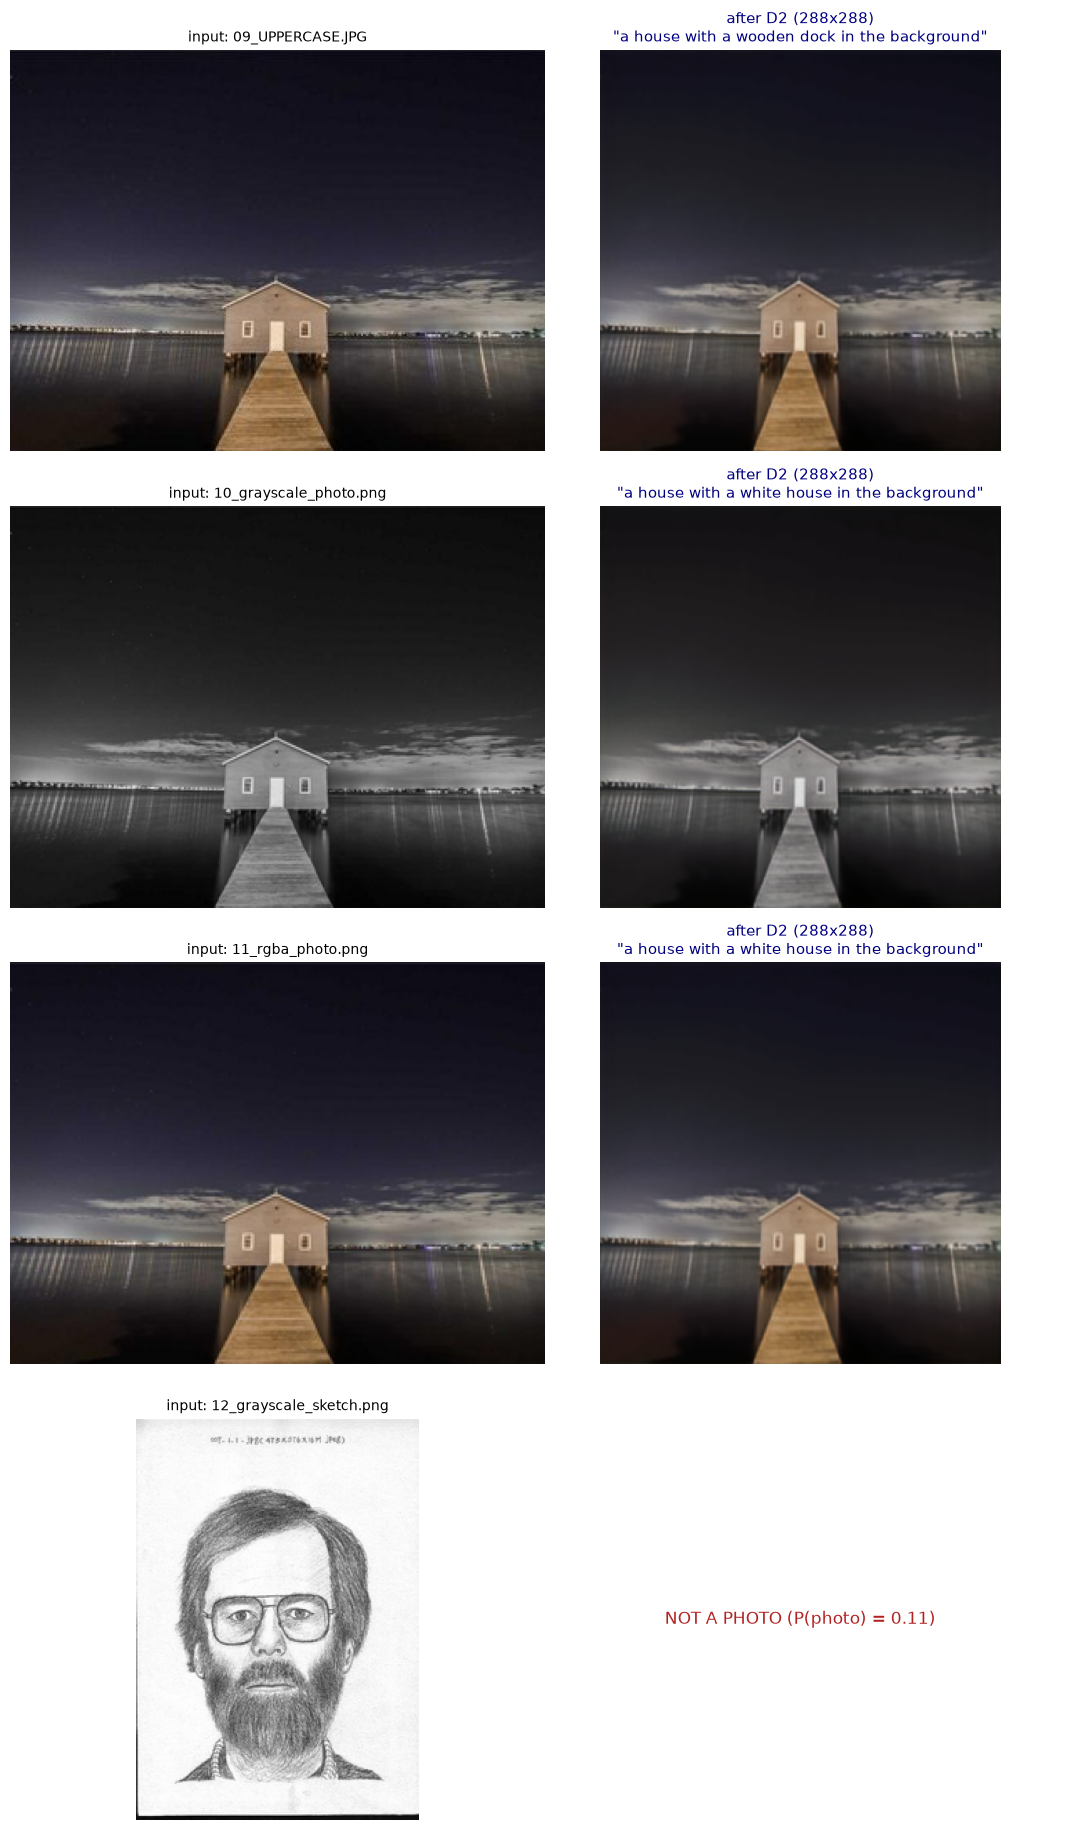

images read          : ['09_UPPERCASE.JPG', '10_grayscale_photo.png', '11_rgba_photo.png', '12_grayscale_sketch.png']
4 images read        : True
sketch stops after D1: True
grey and RGBA photos have a caption: True


In [14]:
edge_items = from_folder("demo_edge_cases")                # prints what is skipped
edge_table = run_pipeline(edge_items)                      # table + figure of the images that were read

# Checks
print("images read          :", [name for name, _ in edge_items])
print("4 images read        :", len(edge_items) == 4)
by_name = edge_table.set_index("image")
print("sketch stops after D1:", by_name.loc["12_grayscale_sketch.png", "D1"] == "not a photo: stop")
print("grey and RGBA photos have a caption:", all(by_name.loc[n, "caption"] != "-" for n in ["10_grayscale_photo.png", "11_rgba_photo.png"]))

demo_images: 7 images read, 0 skipped


,image,size,P(photo),D1,caption,seconds
0,01_clean_photo.png,640x480,0.992000,photo,a house with a wooden dock in the background,1.900000
1,02_noisy_photo.png,480x640,0.986000,photo,a woman sitting on a desk with a laptop,1.700000
2,03_very_noisy_photo.png,480x640,0.897000,photo,a black and white photo of a boat on the water,1.900000
3,04_scan_damaged_photo.png,1024x768,0.998000,photo,a large body of water with a boat on it,1.900000
4,05_blurred_photo.png,480x640,0.594000,photo,a bench sitting on top of a wooden deck,1.700000
5,06_sketch_not_a_photo.jpg,411x583,0.134000,not a photo: stop,-,0.100000
6,07_diagram_not_a_photo.jpg,787x695,0.001000,not a photo: stop,-,0.100000


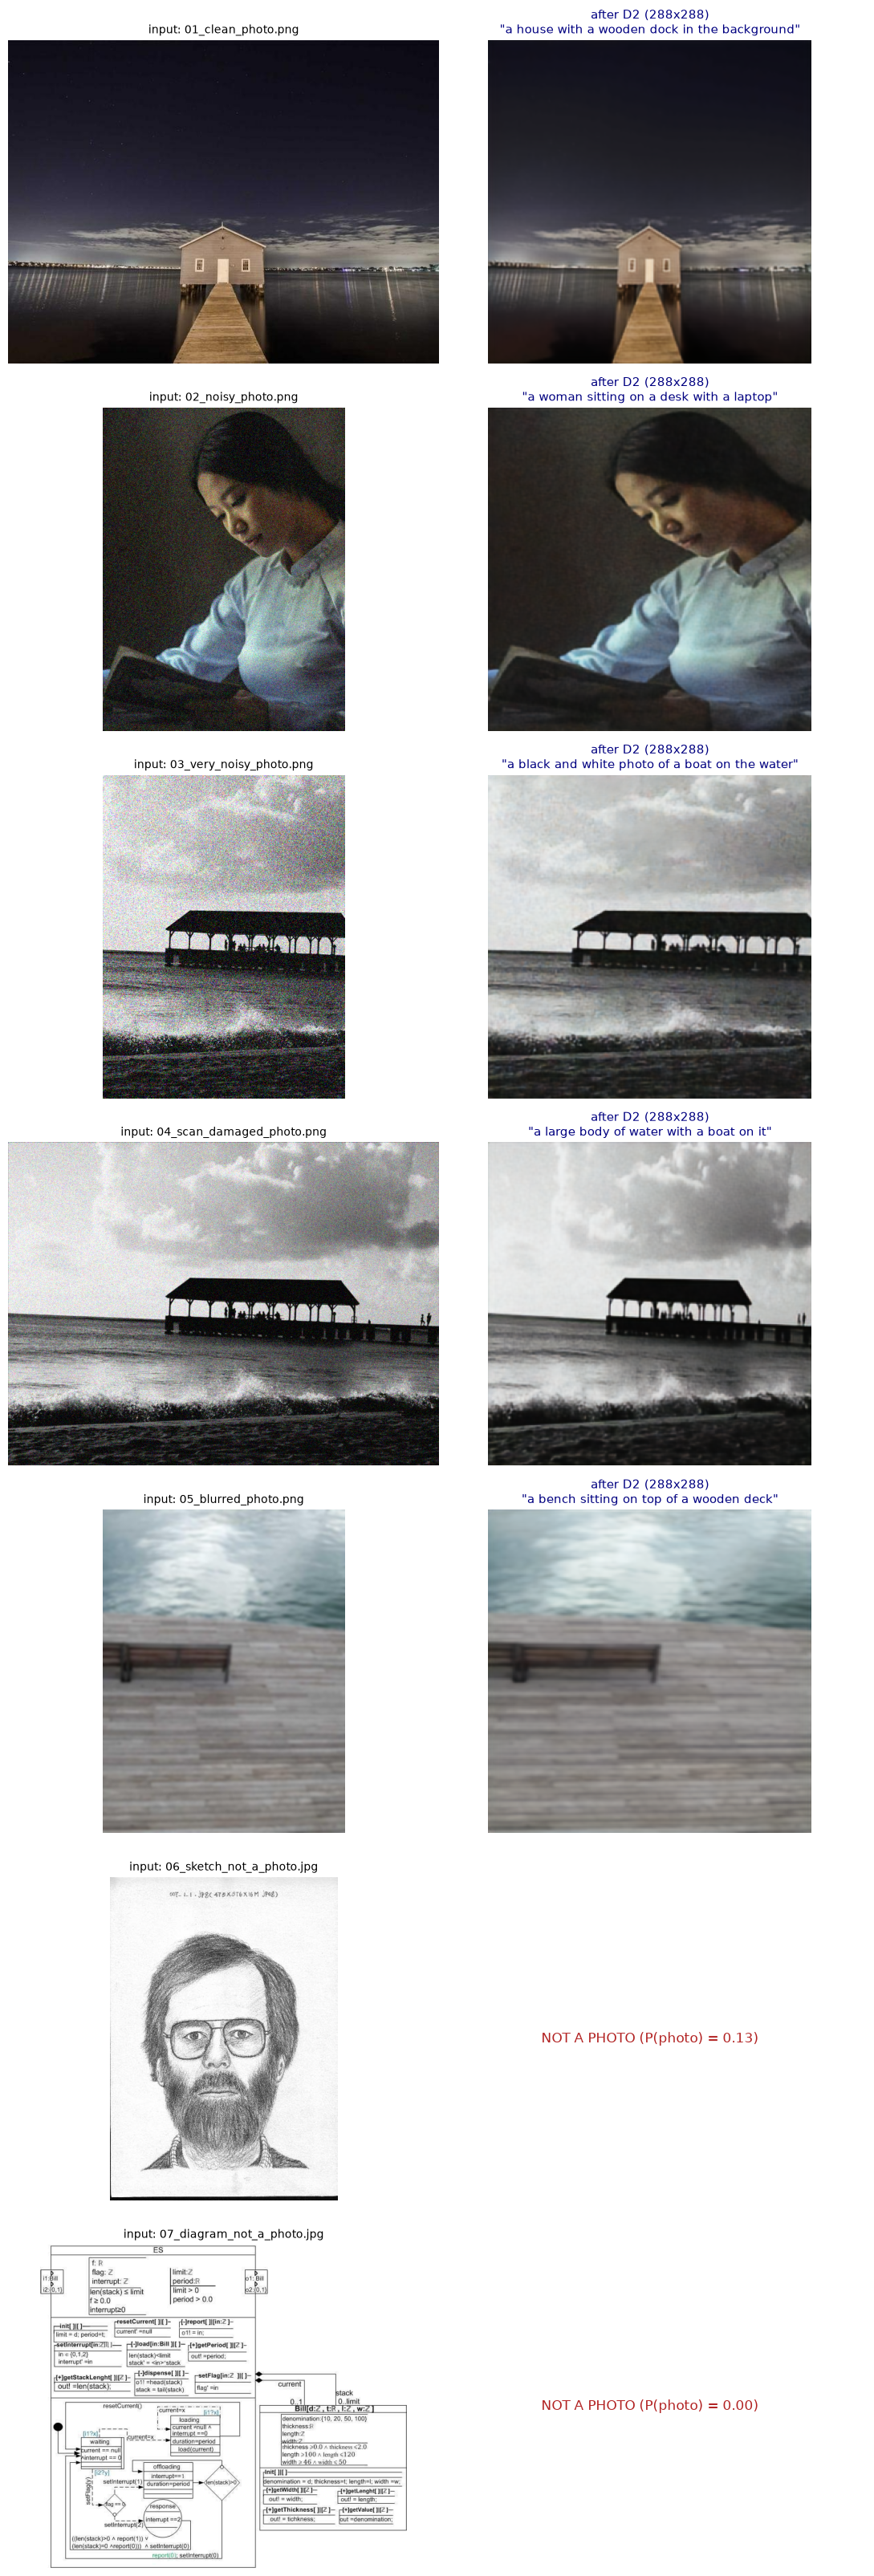

7 images | 5 photos | 2 not photos | total 9 s | table saved to reports/demo_results.csv


In [15]:
INPUT_FOLDER = "demo_images"   # <- the only thing to change: the folder of the evaluation dataset

items = from_folder(INPUT_FOLDER)
assert items, f"no image found in {INPUT_FOLDER}"          # stop with a clear message if the folder has no image
results = run_pipeline(items)                              # D1 -> D2 -> D3 on every image: table + figure
Path("reports").mkdir(exist_ok=True)                       # make sure the folder exists (fresh clone)
results.to_csv("reports/demo_results.csv", index=False)    # the table, one row per image

n_photos = (results["D1"] == "photo").sum()
print(f"{len(results)} images | {n_photos} photos | {len(results) - n_photos} not photos "
      f"| total {results['seconds'].sum():.0f} s | table saved to reports/demo_results.csv")